In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from typing import Dict, List, Union, Optional
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
import seaborn as sns
import os
import datetime
import subprocess
from mech_dot_inp_gen import *
import jinja2
import copy
from Visualization_scripts import *
import math
import hashlib
import pickle
import sqlite3
from matplotlib.colors import Normalize
from matplotlib import cm

In [2]:
abbrevs = {}
with open('split.txt', 'r') as f:
    lines = f.readlines()
    for line in lines:
        abbrev = line.split(' – ')[0]
        meaning = line.split(' – ')[1].strip()
        abbrevs[abbrev] = meaning
print(abbrevs)
with open('splitted.txt', 'w') as ff:
    for k, v in abbrevs.items():
        ff.write(f'{k},{v}\n')

{'AA': 'Amino Acids', 'AARM': 'No such term found, skipped', 'ACD': 'Accidental Cell Death', 'ADP': 'Adenosine Diphosphate', 'AMP': 'Adenosine Monophosphate', 'AMPK': 'AMP-activated Protein Kinase', 'AMPKA': 'Active (phosphorylated) AMPK', 'AMPKA_ADP': 'Active AMPK bound to ADP', 'AMPKA_ADP_PP2A': 'Active AMPK–ADP complex bound to PP2A', 'AMPKA_AMP': 'Active AMPK bound to AMP', 'AMPKA_AMP_PP2A': 'Active AMPK–AMP complex bound to PP2A', 'AMPKA_ATP': 'Active AMPK bound to ATP', 'AMPKA_ATP_PP2A': 'Active AMPK–ATP complex bound to PP2A', 'AMPKA_PP2A': 'Active AMPK bound to PP2A', 'AMPK_ADP': 'AMPK bound to ADP', 'AMPK_ADP_LKB1': 'AMPK–ADP complex bound to LKB1', 'AMPK_AMP': 'AMPK bound to AMP', 'AMPK_AMP_LKB1': 'AMPK–AMP complex bound to LKB1', 'AMPK_ATP': 'AMPK bound to ATP', 'AMPK_ATP_LKB1': 'AMPK–ATP complex bound to LKB1', 'AMPK_LKB1': 'AMPK bound to LKB1', 'APC': 'Not occurring → excluded', 'Apaf-1': 'Apoptotic Protease-Activating Factor 1', 'ATG': 'Autophagy-related Gene/Protein', 'A

In [3]:
class NaturalSelectionCache:
    def __init__(self, path: Union[str, Path]):
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        self.db = sqlite3.connect(path)
        self.db.execute("PRAGMA journal_mode=WAL")
        self.db.execute("PRAGMA synchronous=NORMAL")
        self.db.execute("CREATE TABLE IF NOT EXISTS cache (key TEXT PRIMARY KEY, value BLOB)")

    def get(self, key):
        row = self.db.execute("SELECT value FROM cache WHERE key = ?", (key,)).fetchone()
        return pickle.loads(row[0]) if row else None

    def save(self, key, value):
        self.db.execute(
            "INSERT OR IGNORE INTO cache VALUES (?, ?)",
            (key, sqlite3.Binary(pickle.dumps(value, protocol=pickle.HIGHEST_PROTOCOL))),
        )
        self.db.commit()

In [4]:
class OptimaOutput:
    def __init__(self, job_name: Union[str, Path],
                 optima_path: Optional[Union[str, Path]] = None):

        self.job_name = str(job_name)
        if optima_path == None:
            self.optima_path = Path("/home/szupernikusz/OptimaPP/outputs")
        self.job_folder = self.optima_path / job_name
        file_path = self.job_folder / "mechanismInfo.txt"
        try:
            with open(file_path, "r") as f:
                self.mech_info = f.read()
        except Exception as e:
            raise e

In [5]:
class OptimaMechtest(OptimaOutput):
    def __init__(self, job_name: Union[str, Path],
                 input_mech: str,
                 optima_path: Optional[Union[str, Path]] = None,
                 errf_type: Union[str, List[str]] = "default",
                 cache: Optional[NaturalSelectionCache] = None):
        super().__init__(job_name, optima_path)

        self._errf_files = {
           "default": "errfValues",
           "data_series": "errfValues_by_data_series", 
           "points": "errfValues_by_points",
           "species": "errfValues_by_species"
        }

        result_file = self.job_folder / f"mechTestResults_{input_mech}.csv"
        debug_folder = self.job_folder / "debug"
        source_files = [result_file, debug_folder]
        source_state = [(str(path), path.stat().st_size, path.stat().st_mtime_ns)
                        for path in source_files if path.exists()]
        source_hash = hashlib.sha256(repr(source_state).encode()).hexdigest()
        cache_key = f"v1:{self.job_name}:{input_mech}:{source_hash}"

        cached = cache.get(f"{cache_key}:complete") if cache else None
        if cached is not None:
            self.df_basal = cached['df_basal']
            self.df_followed18 = cached['df_followed18']
            self.failed_sims_xmls = cached['failed_sims_xmls']
            print(f"Loaded {self.job_name} from cache")
            return

        if debug_folder.exists():
            self.all_data = {}
            for csv_data in sorted(debug_folder.glob("*.csv")):
                try:
                    debug_key = f"{cache_key}:debug:{csv_data.stem}"
                    debug_data = cache.get(debug_key) if cache else None
                    if debug_data is None:
                        debug_data = pd.read_csv(csv_data)
                        if cache:
                            debug_data = debug_data.iloc[-1]
                            cache.save(debug_key, debug_data)
                            debug_data = debug_data.to_frame().T
                    elif cache:
                        debug_data = debug_data.to_frame().T
                    self.all_data[csv_data.stem] = debug_data
                except Exception as e:
                    print(e)
        print(result_file)
        if result_file.exists():
            print(result_file.exists())
            self.all_sheets_dP = pd.read_csv(result_file,  # dP as in the info in dataPoints
                                        header=None,
                                        delimiter=';',
                                        index_col=False,
                                        names=['xml', 'time_point', 'species', 'dP_val', 'sim_val'],
                                        )#low_memory=False)
            #print(self.all_sheets_dP)
            self.get_coarse_df(all_sheets_dP=self.all_sheets_dP, cache=cache, cache_key=cache_key)

        stac_eq_df = pd.concat({k: v.iloc[-1] for k, v in self.all_data.items()}, axis=1)                # makes a dict() with the
        #followed18 = pd.concat({k: v.iloc[-1] for k, v in self.orig_time_sim_df.items()}, axis=1)        # same keys, the values are
        self.df_basal = stac_eq_df.iloc[3:-1].T                                                          # the last elements i.e.,
        #self.df_followed18 = followed18.T                                                                # t = last time_point

        if cache:
            cache.save(f"{cache_key}:complete", {
                'df_basal': self.df_basal,
                'df_followed18': self.df_followed18,
                'failed_sims_xmls': self.failed_sims_xmls,
            })

    def __str__(self):
        if not self.df_basal.empty and not self.df_followed18.empty:
            return f"Mech object was successfully generated with fields\ndf_basal: {self.df_basal.shape}\ndf_followed18: {self.df_followed18.shape}"
        elif self.df_basal.empty and not self.df_followed18.empty:
            return "Unsuccessful, error with df_basal"
        elif not self.df_basal.empty and self.df_followed18.empty:
            return "Unsuccessful, error with df_followed18"
        else:
            return "Mech object was not successfully created"

    def get_coarse_df(self, all_sheets_dP, cache=None, cache_key=None):
        self.orig_time_sim_df = {}
        self.orig_time_exp_df = {}
        self.failed_sims_xmls = []

        for xml_name, rows in all_sheets_dP.groupby('xml', sort=False):
            xml_key = f"{cache_key}:xml:{xml_name}"
            processed = cache.get(xml_key) if cache else None

            if processed is None:
                sim_df = pd.DataFrame()
                exp_df = pd.DataFrame()
                failed = False
                time_point = 0
                species = 'ilyen_species_tuti_nem_lesz'

                for _, row in rows.iterrows():
                    if failed:
                        continue

                    if row.species == species:
                        time_point += 1
                    else:
                        species = row.species
                        time_point = 1

                    if row.sim_val != 'FAILED':
                        sim_df.loc[time_point, species] = float(row.sim_val)
                        exp_df.loc[time_point, species] = row.dP_val
                    else:
                        failed = True

                sim_df = sim_df.sort_index().apply(pd.to_numeric, errors='coerce')
                processed = {'sim': sim_df, 'exp': exp_df, 'failed': failed}
                if cache:
                    cache.save(xml_key, processed)

            if not processed['sim'].empty:
                self.orig_time_sim_df[xml_name] = processed['sim']
                self.orig_time_exp_df[xml_name] = processed['exp']
            if processed['failed']:
                self.failed_sims_xmls.append(xml_name)

        # build “followed18” as last valid values per species
        followed18 = pd.concat(
            {xml: df.ffill().iloc[-1]              # or: df.apply(lambda c: c.dropna().iloc[-1])
            for xml, df in self.orig_time_sim_df.items()},
            axis=1
        )
        self.df_followed18 = followed18.T

In [6]:
class Processing:
    def __init__(self, species_txt: str, ) -> None:
        self.species = self.get_species(species_txt)
        self.observables, self.not_observables = self.get_observables()

    def get_species(self, species_txt: str) -> list[str]:
        species = []
        with open(species_txt, 'r') as f:
            lines = f.readlines()
        for line in lines:
            for s in line.strip().split():
                species.append(s)
        print(len(species), species)
        return species

    def get_observables(self) -> tuple[list[str], list[str]]:
        dont_observe = []
        for s in self.species:
            if s == 'Q' or '_LKB1' in s or '_PP2A' in s or 'GLUT1_' in s or 'RAP' in s or 'RK' in s:
                dont_observe.append(s)
            elif s == 'FKBP12' or s == 'REF':
                dont_observe.append(s)
        observe = list(set(self.species) - set(dont_observe))
        print(len(observe), observe)
        return observe, dont_observe

In [7]:
class Model:
    def __init__(self, model_name: str, ics_df_path, # data_source: a pandas DataFrame
                 dont_observe: list[str], time_points: list[float],
                 time_course_vals: Union[dict[str, list[float]], float],
                 food: str, must_be_zero: list[str]=[], uncertainty=False,
                 inputs: dict[str, float]={'GLUCOUT': 6e-6}): # dict[stress_species: init_cc] = [rap extracell.: [mol/cm^3]]
        self.model_name = model_name
        self.ics_df = pd.read_csv(ics_df_path, sep=',')
        self.ics_df['minconc'] = self.ics_df['minconc'].astype(float)
        self.ics_df['maxconc'] = self.ics_df['maxconc'].astype(float)
        self.ics_df['value'] = self.ics_df['value'].astype(float)
        self.ics_df.species = [s.upper() for s in self.ics_df.species]
        self.species = self.ics_df['species'].to_list()
        self.output_species = list(set(self.species) - set(dont_observe))
        self.time_points = time_points
        if isinstance(time_course_vals, float):
            self.time_course_vals = self.gen_time_course_vals(time_course_vals)
        else:
            self.time_course_vals = time_course_vals
        self.food = food
        self.must_be_zero = must_be_zero
        self.uncertainty = uncertainty
        self.inputs = inputs

        self.ranges = self.get_bounds()
        print(f"range values stored in model.ranges of length {len(self.ranges.keys())}")
        self.get_sigmas()
        self.gen_exp_data()

    def get_bounds(self) -> dict[str, tuple[float, float]]:
        bounds = dict()
        for _, row in self.ics_df.iterrows():
            if 'REF' not in row.species and row.species not in self.must_be_zero:
                if row.value < 1e-13:
                    lb = 1e-14
                    ub = 1e-13
                elif row.minconc == row.maxconc:
                    lb = row.minconc
                    ub = row.maxconc
                else:
                    if row.value/2 >= row.minconc:
                        lb = (row.value/2)
                    else:
                        lb = row.minconc
                    if row.value*1.5 <= row.maxconc:
                        ub = (row.value*1.5)
                    else:
                        ub = row.maxconc
            bounds[row.species.upper()] = [lb, ub]
        return bounds

    def get_sigmas(self):
        self.sigmas = dict()
        for key, value in self.ranges.items():
            if self.uncertainty:
                if key in self.must_be_zero: # this line might be unnecessary, as I think we need sigma only if the species is an output
                    self.sigmas[key] = 5e-18
                elif key in self.output_species:
                    if value[1] > value[0]:
                        self.sigmas[key] = ((value[1]-value[0])/8)
                    else:
                        self.sigmas[key] = 5e-13
            else:
                self.sigmas[key] = 2.5e-11

    def gen_time_course_vals(self, time_course_vals):
        species_time_course = {}
        for s in self.species:
            species_time_course[s] = np.ones(len(self.time_points)) * time_course_vals
        return species_time_course

    def gen_exp_data(self):
        self.exp_data = pd.DataFrame()
        self.exp_data['time'] = self.time_points
        for s in self.output_species:
            self.exp_data[s] = self.ics_df[self.ics_df['species'] == s].iloc[0, 2]

In [8]:
class Genesis:
    def __init__(self, model: Model, max_digit = 4):
        self.model = model
        self.maxdigit = max_digit

    def create_xml_files(self, output_xmls_path: str, num_of_xmls: int,
                         xml_template_path: str, prefix: str='', kiir=True) -> None:
        if not os.path.exists(output_xmls_path):
            os.makedirs(output_xmls_path)
        self.num_xmls = num_of_xmls
        self.output_dir = output_xmls_path
        env = jinja2.Environment(loader=jinja2.FileSystemLoader(os.path.dirname(xml_template_path)))
        self.template = env.get_template(os.path.basename(xml_template_path))

        if kiir:
            for i in range(1, num_of_xmls+1):
                np.random.seed(i+1)
                self.random_ics = self.get_random_ics()
                self.make_xml_output(i, output_xmls_path, prefix)

    def get_random_ics(self) -> dict[str, float]:
        random_ics = {}
        if self.model.uncertainty:
            for key in self.model.species:
                if key not in self.model.must_be_zero:
                    random_ics[key] = np.random.uniform(*self.model.ranges[key])
                else:
                    random_ics[key] = 0
        else:
           random_ics = dict(zip(self.model.ics_df['species'], self.model.ics_df['value']))
        for key in self.model.inputs.keys():
            random_ics[key] = self.model.inputs[key]
        random_ics["REF"] = 1.0
        if self.model.food == 'stac':
            random_ics['Q'] = 3e-6
        elif self.model.food == 'bifurc':
            random_ics['Q'] = 3e-7
        return random_ics

    def make_xml_output(self, file_index: int, output_xmls_path: str, prefix) -> None:
        dataPoints = [self.compileDataRow(row.values) for _, row in self.model.exp_data.iterrows()]
        output = self.template.render(ics=self.random_ics, relsigmas=self.model.sigmas,
                                      variables=self.model.output_species, dataPoints=dataPoints)
        padded_number = str(file_index).zfill(self.maxdigit)
        if self.model.food == 'bifurc':
            self.filename = f"{prefix}_{self.model.inputs['GLUCOUT']:.2e}_{padded_number}.xml"
        else:            
            self.filename = f"{prefix}_{padded_number}.xml"
        with open(os.path.join(output_xmls_path, self.filename), 'w') as f:
            f.write(output)

    def compileDataRow(self, dataPoints):
        meas = "".join(f"<{v}>{{:.4e}}</{v}>" for v in self.model.exp_data.columns)
        return f"<dataPoint>{meas.format(*dataPoints)}</dataPoint>"

In [9]:
class Simulation:
    def __init__(self, gen: Genesis, xmls_in_one_opp: int) -> None:
      self.gen = gen
      self.get_xml_vec(xmls_in_one_opp)

    def get_xml_vec(self, xmls_in_one_opp) -> None:
      self.xmls = []
      for i in range(1, self.gen.num_xmls, xmls_in_one_opp):
          xml_cnt = np.arange(i, i+xmls_in_one_opp, 1) 
          self.xmls.append(xml_cnt)

    def opp_gen(self, opp_output_dir, opp_name_prefix, kiir, mech_file, food) -> None:
      self.opps = []
      self.indices = []
      self.food = food
      self.mech_file = mech_file
      self.mech_inp_name = self.mech_file.split('/')[-1].split('.inp')[0]
      for num in self.xmls:
          opp_filename = f"{opp_name_prefix}_{num[-1]}.opp"
          self.opps.append(opp_filename)
          self.indices.append(f"{num[-1]}")
          if kiir:
            opp_content = self.generate_opp_content(xml_folder=self.gen.output_dir,
                                                    num_xmls=num,
                                                    mech_file=mech_file,
                                                    name=self.food)
            with open(os.path.join(opp_output_dir, opp_filename), "w") as f:
              f.write(opp_content)

    def generate_opp_content(self, xml_folder: str, num_xmls: Union[list[int], list[list[int]]],
                             mech_file: str, name: str, time_limit: int = 50, thread_limit: int = 32,
                             settings_tag: str = "systems_biology", solver: str = "cantera") -> str:
      mech_name = mech_file.split('/')[-1].split('.inp')[0]
      yaml = mech_file.split('.inp')[0]

      # Create MECHMOD section
      mechmod = f"""MECHMOD
      USE_NAME         {mech_name}
      MECH_FILE        {mech_file}
      COMPILE_{solver} {yaml}.yaml
      END
      """

      # Create MECHTEST section
      mechtest = f"""MECHTEST
      MECHANISM  {mech_name}
      TIME_LIMIT {time_limit}
      THREAD_LIMIT {thread_limit}
      SETTINGS_TAG {settings_tag}
      FALLBACK_TO_DEFAULT_SETTINGS
      PLOTS FALSE

      SOLVER {solver}
      SAVE_STATES      CSV
      """

      # Add each XML file name
      for xml in num_xmls:
          padded_number = str(xml).zfill(self.gen.maxdigit)
          mechtest += f"      NAME {xml_folder}/{name}_{padded_number}.xml\n"

      mechtest += "END\n"

      return mechmod + "\n" + mechtest

    def sim_runner(self, log_location:str = ''):
      #self.parent_path = Path.cwd().parents[2]
      self.parent_path = os.path.join(Path.cwd().parents[4], "OptimaPP")

      if log_location == '':
        for idx, opp_file in enumerate(self.opps):
            command = ["bin/Release/OptimaPP", f"../Projects/Semmelweis_BCRN/BCRN/1_mechtest/{opp_file}"]
            print(f"Running: {' '.join(command)}")
            subprocess.run(command, check=True, cwd=self.parent_path)
      else:
        for idx, opp_file in enumerate(self.opps):
          command = ["bin/Release/OptimaPP", f"../Projects/Semmelweis_BCRN/BCRN/1_mechtest/{opp_file}"]
          print(f"Running: {' '.join(command)}")
          log_idx = self.xmls[idx][-1]
          with open(f"{log_location}/ECCB26_stac_{log_idx}.txt", "w") as log:
              subprocess.run(command, check=True, stdout=log, stderr=subprocess.STDOUT, cwd=self.parent_path)

In [10]:
class Natural_Selection:
    def __init__(self, sim: Simulation,
                 cache_path: Union[str, Path] = 'natural_selection_cache.sqlite') -> None:
        self.sim = sim
        self.cache = NaturalSelectionCache(cache_path)
        self.sim_data: dict[str, OptimaMechtest] = {}
        self.get_sim_data()
        #self.survival_of_the_fittest()

    def get_sim_data(self) -> None:
        for idx, key in enumerate(self.sim.indices):
            self.sim_data[key] = OptimaMechtest(job_name=self.sim.opps[idx],
                                                input_mech=self.sim.mech_inp_name,
                                                cache=self.cache)

    def sigma_range(self, meas, sim, sigma):
        radius = (sim-meas)/sigma
        return radius
    
    def isit_init(self, row):
        lut = self.sim.gen.model.ics_df
        rel_sigmas = self.sim.gen.model.sigmas
        for k, v in row.items():
            if k in self.condition_vars:
                right_row = lut[lut['species'] == k]

                meas = right_row['value'].iloc[0]

                radius = self.sigma_range(meas=meas, sim=v, sigma=rel_sigmas[k])

                if radius >= 4:
                    self.wrongdoers[k] += 1
                    return False

        return True
    
    def survival_of_the_fittest(self) -> None:
        self.good_xmls = []
        self.get_condition_vars()
        self.wrongdoers = {k: 0 for k in self.condition_vars}
        for idx in self.sim.indices:
            for xml_name, row in self.sim_data[idx].df_followed18.iterrows():
                all_ok = self.isit_init(row)
                if all_ok:
                    self.good_xmls.append(xml_name)
        print(f"Found {len(self.good_xmls)} good xmls")

    def get_condition_vars(self) -> None:
        self.condition_vars = ['RHEBA', 'AKTA', 'TSC', 'MTORA', 'ATP', 'ULK', 'GLUCIN']
# too big LKB1 activity could mean upregged AMPK biologically speaking
# ADP, AMP make complexes just like ATP, but for AMP/ADP the complex concentrations are comparable to the
# cc. of either ADP or AMP --> complex-bound ADP/AMP would throw the calculation off
# LKB1 and PP2A form complexes with the AMPKs --> their cc. should change --> not adequate conditions
    def filtering(self) -> None:
        data = copy.deepcopy(self.sim_data)
        first = True
        self.filtered_basal = pd.DataFrame()
        self.filtered_followed = pd.DataFrame()
        for k, v in data.items():
            v.df_basal.index = v.df_basal.index.str[7:-9]
            v.df_basal = v.df_basal.sort_index()
            if first:
                self.filtered_basal = v.df_basal[[xml in self.good_xmls for xml in v.df_basal.index]]
                self.filtered_followed = v.df_followed18[[xml in self.good_xmls for xml in v.df_followed18.index]]
                first = False
            else:
                self.filtered_basal = pd.concat([self.filtered_basal, v.df_basal[[xml in self.good_xmls for xml in v.df_basal.index]]],
                                        ignore_index=False)
                self.filtered_followed = pd.concat([self.filtered_followed, v.df_followed18[[xml in self.good_xmls for xml in v.df_followed18.index]]],
                                            ignore_index=False)

    def get_cov_cor(self, corr_xmls, keys: list[str]) -> None:
        self.dict_b = {}
        self.dict_f = {}
        self.dict_b_corr = {}
        self.dict_f_corr = {}
        self.dict_b_cov = {}
        self.dict_f_cov = {}
        for idx, alma in enumerate(corr_xmls):
            self.dict_f[f"{keys[idx]}"] = self.filtered_followed.iloc[alma].copy()
            #self.dict_b[f"{keys[idx]}"] = self.filtered_basal.iloc[alma].copy()
            #self.dict_b_corr[f"{keys[idx]}"] = self.filtered_basal.iloc[alma].copy().corr()
            self.dict_f_corr[f"{keys[idx]}"] = self.filtered_followed.iloc[alma].copy().corr()
            self.dict_f_cov[f"{keys[idx]}"] = self.filtered_followed.iloc[alma].copy().cov()
            #self.dict_b_cov[f"{keys[idx]}"] = self.filtered_basal.iloc[alma].copy().cov()

In [11]:
def plot_correlation_distance_heatmap(dict, corr_xmls, title: str, method='fro',
                                      save_fig=False, nat_select:Natural_Selection=None):
    num_corrs = len(corr_xmls)
    distance_matrix = np.zeros((num_corrs, num_corrs))

    for i, n1 in enumerate(corr_xmls):
        for j, n2 in enumerate(corr_xmls):
            mat1 = dict[str(n1)].values
            mat2 = dict[str(n2)].values
            if method == 'kl':
                mu1 = nat_select.dict_f[str(n1)].mean()
                mu2 = nat_select.dict_f[str(n2)].mean()
                distance_matrix[i, j] = compute_matrix_distance(mat1, mat2, method=method, mu1=mu1, mu2=mu2)
            else:
                distance_matrix[i, j] = compute_matrix_distance(mat1, mat2, method=method)
    plot_it(distance_matrix, corr_xmls, corr_xmls, method, save_fig, title)

def plot_dual_metric_heatmap(dict, keys,
                              method_lower='cmd', method_upper='frobenius',
                              title='Dual Distance Plot',
                              cmap_lower='Blues', cmap_upper='Reds',
                              save_fig=False,
                              nat_select_dict: dict[str, pd.DataFrame] = None):
    n = len(keys)
    data_lower = np.zeros((n, n))
    data_upper = np.zeros((n, n))

    # Compute both metrics for all pairs
    for i, n1 in enumerate(keys):
        for j, n2 in enumerate(keys):
            mat1 = dict[str(n1)]
            mat2 = dict[str(n2)]
            if method_lower == 'kl' or method_upper == 'kl':
                mu1 = nat_select_dict[str(n1)].mean()
                mu2 = nat_select_dict[str(n2)].mean()
            if i >= j:
                data_lower[i, j] = compute_matrix_distance(mat1, mat2, method_lower, mu1=mu1, mu2=mu2)
            elif i < j:
                data_upper[i, j] = compute_matrix_distance(mat1, mat2, method_upper, mu1=mu1, mu2=mu2)

    # Create masks
    mask_lower = np.triu(np.ones_like(data_lower, dtype=bool), k=1)
    mask_upper = np.tril(np.ones_like(data_upper, dtype=bool), k=0)

    fig, ax = plt.subplots(figsize=(8, 6))

    # Plot lower triangle
    norm_lower = Normalize(vmin=np.min(data_lower[np.tril_indices(n, -1)]),
                           vmax=np.max(data_lower[np.tril_indices(n, -1)]))
    sns.heatmap(data_lower,
                mask=mask_lower,
                cmap=cmap_lower,
                annot=True,
                square=True,
                linewidths=0.5,
                cbar=False,
                xticklabels=False,
                yticklabels=False,
                ax=ax)

    plt.xlabel('Number of XMLs')
    plt.ylabel('Number of XMLs')

    # Plot upper triangle
    norm_upper = Normalize(vmin=np.min(data_upper[np.triu_indices(n, 1)]),
                           vmax=np.max(data_upper[np.triu_indices(n, 1)]))
    sns.heatmap(data_upper,
                mask=mask_upper,
                cmap=cmap_upper,
                annot=True,
                square=True,
                linewidths=0.5,
                cbar=False,
                xticklabels=keys,
                yticklabels=keys,
                ax=ax)

    ax.set_xticklabels(keys, rotation=45, ha='right', fontsize=9)
    ax.set_yticklabels(keys, rotation=0, fontsize=9)
    ax.set_title(title, fontsize=14, pad=12)

    # Add both colorbars
    cbar_ax1 = fig.add_axes([0.84, 0.25, 0.02, 0.5])  # Right colorbar
    sm1 = cm.ScalarMappable(cmap=cmap_upper, norm=norm_upper)
    sm1.set_array([])
    cbar1 = fig.colorbar(sm1, cax=cbar_ax1)
    cbar1.set_label(f'{method_upper.upper()} (upper)', rotation=270, labelpad=15)

    cbar_ax2 = fig.add_axes([0.0, 0.25, 0.02, 0.5])  # Left colorbar
    sm2 = cm.ScalarMappable(cmap=cmap_lower, norm=norm_lower)
    sm2.set_array([])
    cbar2 = fig.colorbar(sm2, cax=cbar_ax2)
    cbar2.set_label(f'{method_lower.upper()} (lower)', rotation=90, labelpad=15)

    #fig.patch.set_facecolor('#f8f6f6')
    #plt.tight_layout(rect=[0.1, 0, 0.9, 1])

    if save_fig:
        plt.savefig(f"pics/{title.replace(' ', '_')}.png", dpi=300)
        plt.savefig(f"pics/{title.replace(' ', '_')}.pdf")

    plt.show()

def plot_correlation_distance_heatmap_leodit(dict, corr_xmls, title: str, method='frobenius',
                                      save_fig=False, nat_select:Natural_Selection=None):
    num_corrs = len(corr_xmls)
    distance_matrix = np.zeros((num_corrs, num_corrs))

    for i, n1 in enumerate(corr_xmls):
        for j, n2 in enumerate(corr_xmls):
            mat1 = dict[str(n1)]
            mat2 = dict[str(n2)]
            if method == 'kl':
                mu1 = nat_select.dict_b[str(n1)].mean()
                mu2 = nat_select.dict_b[str(n2)].mean()
                distance_matrix[i, j] = compute_matrix_distance(mat1, mat2, method=method, mu1=mu1, mu2=mu2)
            else:
                distance_matrix[i, j] = compute_matrix_distance(mat1, mat2, method=method)
    plot_it(distance_matrix, corr_xmls, corr_xmls, method, save_fig, title)

In [12]:
reacs_rates=pd.read_csv('reactions_and_constants.csv', sep=',')
reacs_rates = reacs_rates.drop('dummy', axis=1)
reacs_rates.to_csv('reacs_rates_no_ws.csv')

In [13]:
a = ['LKB1', 'AMPKA_ADP', 'AMP', 'ULK', 'PP2A', 'AMPKA_AMP', 'AKT', 'GLUCOUT', 'AMPKA_ATP', 'PYRUVATE', 'GLUT1', 'AMPK_ATP', 'MTORA', 'RHEB', 'RHEBA', 'GLUCIN', 'TSC', 'ULKA', 'AMPK_ADP', 'AMPK', 'AMPK_AMP', 'MTOR', 'AKTA', 'ATP', 'TSCA', 'ADP', 'AMPKA']

In [14]:
proc = Processing('species.txt')

44 ['PYRUVATE', 'Q', 'ATP', 'ADP', 'AMP', 'AMPK', 'LKB1', 'PP2A', 'AMPK_ATP', 'AMPK_ADP', 'AMPK_AMP', 'AMPKA', 'AMPKA_ATP', 'AMPKA_ADP', 'AMPKA_AMP', 'AMPK_LKB1', 'AMPK_ATP_LKB1', 'AMPK_ADP_LKB1', 'AMPK_AMP_LKB1', 'AMPKA_PP2A', 'AMPKA_ATP_PP2A', 'AMPKA_ADP_PP2A', 'AMPKA_AMP_PP2A', 'GLUCOUT', 'GLUT1', 'GLUCIN', 'GLUT1_GLUCOUT', 'GLUT1_GLUCIN', 'AKT', 'AKTA', 'MTOR', 'MTORA', 'RHEB', 'RHEBA', 'TSC', 'TSCA', 'ULK', 'ULKA', 'RAP', 'RK', 'FKBP12', 'RKMTORA', 'RAPOUT', 'REF']
27 ['RHEB', 'GLUT1', 'PP2A', 'AMPKA', 'AMPK_ATP', 'AMPKA_ATP', 'TSC', 'MTORA', 'ADP', 'ATP', 'AMPK', 'ULK', 'ULKA', 'RHEBA', 'AMPK_AMP', 'LKB1', 'AMPKA_AMP', 'AKTA', 'MTOR', 'TSCA', 'PYRUVATE', 'AMP', 'GLUCIN', 'AKT', 'AMPK_ADP', 'AMPKA_ADP', 'GLUCOUT']


In [15]:
t = np.arange(0, 1500, 60)
food = 'stac'
must_be_zero = ['RAP', 'RK', 'RKMTORA', 'RAPOUT']
date = datetime.datetime.now()
date_prefix = 2026814 #f"{date.year}{date.month}{date.day}"

mod = Model(model_name='gluc_rap_mTOR', ics_df_path='../input_files/species_ics_ranges.csv',
            dont_observe=proc.not_observables, time_points=t, time_course_vals=7e-10,
            must_be_zero=must_be_zero, uncertainty=True, inputs={'GLUCOUT': 6e-6}, food=food)

range values stored in model.ranges of length 44


In [16]:
gen = Genesis(mod, max_digit=5)
gen.create_xml_files(f'/home/szupernikusz/Projects/Semmelweis_BCRN/BCRN/xml/{date_prefix}_stac', num_of_xmls=30000,
                     xml_template_path='../input_files/std_xml_template.xml', prefix='stac', kiir=False)

In [17]:
sim = Simulation(gen, 5000)

sim.opp_gen(opp_output_dir=f'/home/szupernikusz/Projects/Semmelweis_BCRN/BCRN/1_mechtest/',
            opp_name_prefix=f'{date_prefix}_ECCB26_stac_30K',
            kiir=False, mech_file='../Projects/Semmelweis_BCRN/BCRN/mech/Minimal_gluc_rap_mTOR_v1.inp',
            food='stac')

In [18]:
#sim.sim_runner(f'/home/szupernikusz/Projects/Semmelweis_BCRN/BCRN/logs/ECCB26_stac50K')

In [20]:
nat = Natural_Selection(sim, cache_path='data/natural_selection_cache.sqlite')

Loaded 2026814_ECCB26_stac_30K_5000.opp from cache
Loaded 2026814_ECCB26_stac_30K_10000.opp from cache
Loaded 2026814_ECCB26_stac_30K_15000.opp from cache
Loaded 2026814_ECCB26_stac_30K_20000.opp from cache
Loaded 2026814_ECCB26_stac_30K_25000.opp from cache
Loaded 2026814_ECCB26_stac_30K_30000.opp from cache


In [21]:
nat.survival_of_the_fittest()

Found 29840 good xmls


In [22]:
nat.filtering()

In [23]:
corr_xmls = [np.arange(0, 32, 1), np.arange(32, 96, 1), np.arange(96, 224, 1), np.arange(224, 480, 1),
                 np.arange(480, 992, 1), np.arange(992, 2016, 1), np.arange(2016, 4064, 1), np.arange(4064, 8160, 1),
                 np.arange(8160, 16352, 1), np.arange(16352, len(nat.good_xmls), 1)]#, np.arange(0, len(nat.good_xmls), 1)]
keys = [str(len(a)) for a in corr_xmls]
print(len(nat.good_xmls), keys)
nat.get_cov_cor(corr_xmls, keys)

29840 ['32', '64', '128', '256', '512', '1024', '2048', '4096', '8192', '13488']


In [32]:
corr_xmls = [np.arange(0, 50, 1), np.arange(50, 500, 1), np.arange(500, 1500, 1), np.arange(1500, 4500, 1),
                 np.arange(4500, 10000, 1), np.arange(10000, len(nat.good_xmls), 1)]
keys = ['50', '450', '1000', '3000', '5500', f"{20000 - 10000}"]
print(len(nat.good_xmls))
nat.get_cov_cor(corr_xmls, keys)

29840


In [76]:
def correlation_matrix_distance(A, B):
    """Correlation Matrix Distance (CMD), Herdin et al. (2005), https://doi.org/10.1049/el:20057319"""
    numerator = np.trace(A @ B)
    denominator = np.linalg.norm(A, 'fro') * np.linalg.norm(B, 'fro')
    return 1 - (numerator / denominator)

def rv_coefficient(A, B):
    """RV Coefficient, Escoufier (1973), https://doi.org/10.1016/0378-3758(78)90121-8"""
    numerator = np.trace(A @ B)
    denominator = np.sqrt(np.trace(A @ A) * np.trace(B @ B))
    return numerator / denominator

def safe_airm(A, B, epsilon=1e+1):
    """If COV() matrix is singular, https://doi.org/10.1016/S0047-259X(03)00096-4"""
    A_spd = A + epsilon * np.eye(A.shape[0])
    B_spd = B + epsilon * np.eye(B.shape[0])
    A_inv_sqrt = np.linalg.inv(sqrtm(A_spd))
    log_term = logm(A_inv_sqrt @ B_spd @ A_inv_sqrt)
    return np.linalg.norm(log_term, 'fro')

def affine_invariant_riemannian(A, B):
    """Affine-Invariant Riemannian Distance, https://doi.org/10.1007/s11263-005-3222-z"""
    try:
        A_inv_sqrt = np.linalg.inv(sqrtm(A))
        log_term = logm(A_inv_sqrt @ B @ A_inv_sqrt)
        return np.linalg.norm(log_term, 'fro')
    except:
        print("Matrix is singular, switching to linear shrinkage estimator formula")
        safe_airm(A, B)

def bures_wasserstein_distance(A, B):
    """Bures–Wasserstein Distance, https://doi.org/10.1016/0047-259X(82)90077-X"""
    sqrtA = sqrtm(A)
    middle = sqrtm(sqrtA @ B @ sqrtA)
    return np.sqrt(np.trace(A + B - 2 * middle))

def root_stein_divergence(A, B):
    """Root Stein Divergence, Sra, A New Metric on the Manifold of Kernel Matrices with Application to Matrix Geometric Means, NIPS, 2012"""
    sqrt_product = sqrtm(A @ B)
    return np.trace(A + B - 2 * sqrt_product)

def compute_matrix_distance(mat1, mat2, method='fro', mu1=1, mu2=1):
    if method == 'frobenius':
        return np.linalg.norm(mat1 - mat2, ord='fro')
    elif method == 'cmd':
        return correlation_matrix_distance(mat1, mat2)
    elif method == 'rv':
        return rv_coefficient(mat1, mat2)
    elif method == 'airm':
        return affine_invariant_riemannian(mat1, mat2)
    elif method == 'bures':
        return bures_wasserstein_distance(mat1, mat2)
    elif method == 'rsd':
        return root_stein_divergence(mat1, mat2)
    elif method == 'kl':
        return kl_mvn(mu1, mat1, mu2, mat2)
    else:
        raise ValueError("Unknown method. Use 'frobenius', 'cmd', 'rv', 'airm', 'skl', 'bures', or 'rsd'.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable


def plot_dual_metric_heatmap_stable(
    cov_dict, keys,
    method_lower='cmd', method_upper='frobenius',
    title='Dual Distance Plot',
    cmap_lower='Blues', cmap_upper='Reds',
    save_fig=False,
    nat_select_dict: dict[str, pd.DataFrame] = None,
    mu1=1, mu2=1,
    figsize=(8, 6)
):
    n = len(keys)
    data_lower = np.zeros((n, n))
    data_upper = np.zeros((n, n))

    # Compute both metrics for all pairs
    for i, n1 in enumerate(keys):
        for j, n2 in enumerate(keys):
            mat1 = cov_dict[str(n1)] * 1e+9  # scaling back from 1e-9 M to uM
            mat2 = cov_dict[str(n2)] * 1e+9

            curr_mu1, curr_mu2 = mu1, mu2
            if method_lower == 'kl' or method_upper == 'kl':
                curr_mu1 = nat_select_dict[str(n1)].mean()
                curr_mu2 = nat_select_dict[str(n2)].mean()

            if i >= j:
                data_lower[i, j] = compute_matrix_distance(
                    mat1, mat2, method_lower, mu1=curr_mu1, mu2=curr_mu2
                )
            else:
                data_upper[i, j] = compute_matrix_distance(
                    mat1, mat2, method_upper, mu1=curr_mu1, mu2=curr_mu2
                )

    # Create masks
    mask_lower = np.triu(np.ones_like(data_lower, dtype=bool), k=1)
    mask_upper = np.tril(np.ones_like(data_upper, dtype=bool), k=0)

    # Norms for colorbars / heatmaps
    lower_vals = data_lower[np.tril_indices(n, -1)]
    upper_vals = data_upper[np.triu_indices(n, 1)]

    norm_lower = Normalize(vmin=np.min(lower_vals), vmax=np.max(lower_vals))
    norm_upper = Normalize(vmin=np.min(upper_vals), vmax=np.max(upper_vals))

    fig, ax = plt.subplots(figsize=figsize)
    fig.set_dpi(450)

    # Plot lower triangle
    sns.heatmap(
        data_lower,
        mask=mask_lower,
        cmap=cmap_lower,
        norm=norm_lower,
        annot=True,
        square=True,
        linewidths=0.5,
        cbar=False,
        xticklabels=False,
        yticklabels=False,
        ax=ax
    )

    # Plot upper triangle
    sns.heatmap(
        data_upper,
        mask=mask_upper,
        cmap=cmap_upper,
        norm=norm_upper,
        annot=True,
        square=True,
        linewidths=0.5,
        cbar=False,
        xticklabels=keys,
        yticklabels=keys,
        ax=ax
    )

    ax.set_xticklabels(keys, rotation=45, ha='right', fontsize=14)
    ax.set_yticklabels(keys, rotation=0, fontsize=14)
    ax.set_title(title, fontsize=20, pad=12)
    ax.set_xlabel('Number of XMLs', fontsize=16)
    ax.set_ylabel('Number of XMLs', fontsize=16)

    # Add both colorbars right next to the heatmap
    divider = make_axes_locatable(ax)
    cbar_ax_left = divider.append_axes("left", size="3%", pad=0.25)
    cbar_ax_right = divider.append_axes("right", size="3%", pad=0.25)

    sm_lower = cm.ScalarMappable(cmap=cmap_lower, norm=norm_lower)
    sm_lower.set_array([])
    cbar_lower = fig.colorbar(sm_lower, cax=cbar_ax_left)
    cbar_lower.set_label(f'{method_lower.upper()} (lower)', rotation=90, labelpad=15)
    cbar_ax_left.yaxis.set_ticks_position('left')
    cbar_ax_left.yaxis.set_label_position('left')

    sm_upper = cm.ScalarMappable(cmap=cmap_upper, norm=norm_upper)
    sm_upper.set_array([])
    cbar_upper = fig.colorbar(sm_upper, cax=cbar_ax_right)
    cbar_upper.set_label(f'{method_upper.upper()} (upper)', rotation=270, labelpad=15)

    if save_fig:
        plt.savefig(f"pics/{title.replace(' ', '_')}.png", dpi=300, bbox_inches='tight')
        plt.savefig(f"pics/{title.replace(' ', '_')}.pdf", bbox_inches='tight')

    plt.show()

def plot_correlation_distance_heatmap_leodit(dict, corr_xmls, title: str, method='frobenius',
                                      save_fig=False, nat_select:Natural_Selection=None):
    num_corrs = len(corr_xmls)
    distance_matrix = np.zeros((num_corrs, num_corrs))

    for i, n1 in enumerate(corr_xmls):
        for j, n2 in enumerate(corr_xmls):
            mat1 = dict[str(n1)]
            mat2 = dict[str(n2)]
            if method == 'kl':
                mu1 = nat_select.dict_b[str(n1)].mean()
                mu2 = nat_select.dict_b[str(n2)].mean()
                distance_matrix[i, j] = compute_matrix_distance(mat1, mat2, method=method, mu1=mu1, mu2=mu2)
            else:
                distance_matrix[i, j] = compute_matrix_distance(mat1, mat2, method=method)
    plot_it(distance_matrix, corr_xmls, corr_xmls, method, save_fig, title)


In [77]:
from sklearn.covariance import empirical_covariance, ledoit_wolf

dict_leodian_cov = {}
shrinkage = {}

for k in keys:
    dict_leodian_cov[k], shrinkage[k] = ledoit_wolf(nat.dict_f[k])

In [78]:
from sklearn.covariance import empirical_covariance, ledoit_wolf

dict_leodian = {}
shrinkage = {}

for k in keys:
    dict_leodian[k], shrinkage[k] = ledoit_wolf(nat.dict_f[k])

ok = 1

for k, v in dict_leodian.items():
    try:
        np.linalg.cholesky(dict_leodian[k])
    except:
        print('Ajjaj')
        ok = 0
        break

if ok:
    print("All matrices are positive definite")
    print(shrinkage)

All matrices are positive definite
{'50': np.float64(0.016501238236276652), '450': np.float64(0.002389722408781697), '1000': np.float64(0.0011116136781086138), '3000': np.float64(0.0003658765633871955), '5500': np.float64(0.00020279393960158888), '10000': np.float64(5.5810411749936903e-05)}


In [150]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from matplotlib.colors import Normalize


def plot_dual_metric_heatmap_stable(
    cov_dict, keys,
    method_lower='cmd', method_upper='frobenius',
    title='Dual Distance Plot',
    cmap_lower='Blues', cmap_upper='Reds',
    save_fig=False,
    nat_select_dict: dict[str, pd.DataFrame] = None,
    mu1=1, mu2=1,
    figsize=(8, 6),
    cbar_width=0.035,
    cbar_spacing=0.25
):
    n = len(keys)
    data_lower = np.zeros((n, n))
    data_upper = np.zeros((n, n))

    # Compute both metrics for all pairs
    for i, n1 in enumerate(keys):
        for j, n2 in enumerate(keys):
            mat1 = cov_dict[str(n1)] * 1e+9  # scaling back from 1e-9 M to uM
            mat2 = cov_dict[str(n2)] * 1e+9

            curr_mu1, curr_mu2 = mu1, mu2

            if method_lower == 'kl' or method_upper == 'kl':
                curr_mu1 = nat_select_dict[str(n1)].mean()
                curr_mu2 = nat_select_dict[str(n2)].mean()

            if i >= j:
                data_lower[i, j] = compute_matrix_distance(
                    mat1, mat2, method_lower,
                    mu1=curr_mu1, mu2=curr_mu2
                )
            else:
                data_upper[i, j] = compute_matrix_distance(
                    mat1, mat2, method_upper,
                    mu1=curr_mu1, mu2=curr_mu2
                )

    # Masks
    mask_lower = np.triu(np.ones_like(data_lower, dtype=bool), k=1)
    mask_upper = np.tril(np.ones_like(data_upper, dtype=bool), k=0)

    # Color normalization
    lower_vals = data_lower[np.tril_indices(n, -1)]
    upper_vals = data_upper[np.triu_indices(n, 1)]

    norm_lower = Normalize(
        vmin=np.min(lower_vals),
        vmax=np.max(lower_vals)
    )
    norm_upper = Normalize(
        vmin=np.min(upper_vals),
        vmax=np.max(upper_vals)
    )

    # ---------------------------------------------------------
    # Figure layout:
    # [left colorbar]  [heatmap]  [right colorbar]
    # ---------------------------------------------------------
    fig = plt.figure(figsize=figsize, layout='constrained')
    fig.set_dpi(450)

    gs = fig.add_gridspec(
        1, 3,
        width_ratios=[cbar_width, 1, cbar_width],
        wspace=cbar_spacing
    )

    display_heatmap = False
    if display_heatmap:
        ax = fig.add_subplot(gs[1])

        import re

        def format_sci(x):
            s = f"{x:.2g}"
            return re.sub(r'e([+-])0+(\d+)', r'e\1\2', s)

        annot_upper = np.vectorize(format_sci)(data_upper)
        annot_lower = np.vectorize(format_sci)(data_lower)

        # Lower triangle
        sns.heatmap(
            data_lower,
            mask=mask_lower,
            cmap=cmap_lower,
            norm=norm_lower,
            annot=annot_lower,
            fmt="",
            annot_kws={"fontsize": 13},
            square=True,
            linewidths=0.5,
            cbar=False,
            xticklabels=False,
            yticklabels=False,
            ax=ax
        )

        # Upper triangle
        sns.heatmap(
            data_upper,
            mask=mask_upper,
            cmap=cmap_upper,
            norm=norm_upper,
            annot=annot_upper,
            fmt="",
            annot_kws={"fontsize": 13},
            square=True,
            linewidths=0.5,
            cbar=False,
            xticklabels=keys,
            yticklabels=keys,
            ax=ax
        )

        # Axes formatting
        ax.set_xticklabels(
            keys,
            rotation=45,
            ha='right',
            fontsize=20,
        )

        ax.set_yticklabels(
            keys,
            rotation=0,
            fontsize=20,
        )

        ax.tick_params(axis='x', pad=-4)
        ax.tick_params(axis='y', pad=0)

        ax.set_title(
            title,
            fontsize=20,
            #pad=12
        )

        ax.set_xlabel(
            'Number of XMLs',
            fontsize=30,
            labelpad=-2
        )

        ax.set_ylabel(
            'Number of XMLs',
            fontsize=30,
            labelpad=-4
        )

    display_colorbars = True
    if display_colorbars:
        cbar_ax_left = fig.add_subplot(gs[0])
        cbar_ax_right = fig.add_subplot(gs[2])

        # ---------------------------------------------------------
        # Left colorbar
        # ---------------------------------------------------------
        sm_lower = cm.ScalarMappable(
            cmap=cmap_lower,
            norm=norm_lower
        )
        sm_lower.set_array([])

        cbar_lower = fig.colorbar(
            sm_lower,
            cax=cbar_ax_left
        )

        cbar_lower.set_label(
            f'',#{method_lower.upper()} (lower)',
            fontsize=20,
            rotation=90,
            labelpad=0
        )

        cbar_ax_left.yaxis.set_ticks_position('left')
        cbar_ax_left.yaxis.set_label_position('left')

        # ---------------------------------------------------------
        # Right colorbar
        # ---------------------------------------------------------
        sm_upper = cm.ScalarMappable(
            cmap=cmap_upper,
            norm=norm_upper
        )
        sm_upper.set_array([])

        cbar_upper = fig.colorbar(
            sm_upper,
            cax=cbar_ax_right
        )

        cbar_upper.set_label(
            f'',#{method_upper.upper()} (upper)',
            fontsize=20,
            rotation=270,
            labelpad=10
        )

    cbar_ax_left.tick_params(axis='y', labelsize=20)
    cbar_ax_right.tick_params(axis='y', labelsize=20)

    # Save
    if save_fig:
        filename = title.replace(' ', '_')

        plt.savefig(
            f"pics/{filename}.png",
            dpi=300,
            bbox_inches='tight'
        )

        plt.savefig(
            f"pics/{filename}.pdf",
            bbox_inches='tight'
        )

    plt.show()

/tmp/ipykernel_1169063/3352947062.py:25: RuntimeWarning: logm result may be inaccurate, approximate err = 3.4305839631128796e-13
  log_term = logm(A_inv_sqrt @ B @ A_inv_sqrt)
/tmp/ipykernel_1169063/3352947062.py:25: RuntimeWarning: logm result may be inaccurate, approximate err = 3.39513654516647e-13
  log_term = logm(A_inv_sqrt @ B @ A_inv_sqrt)


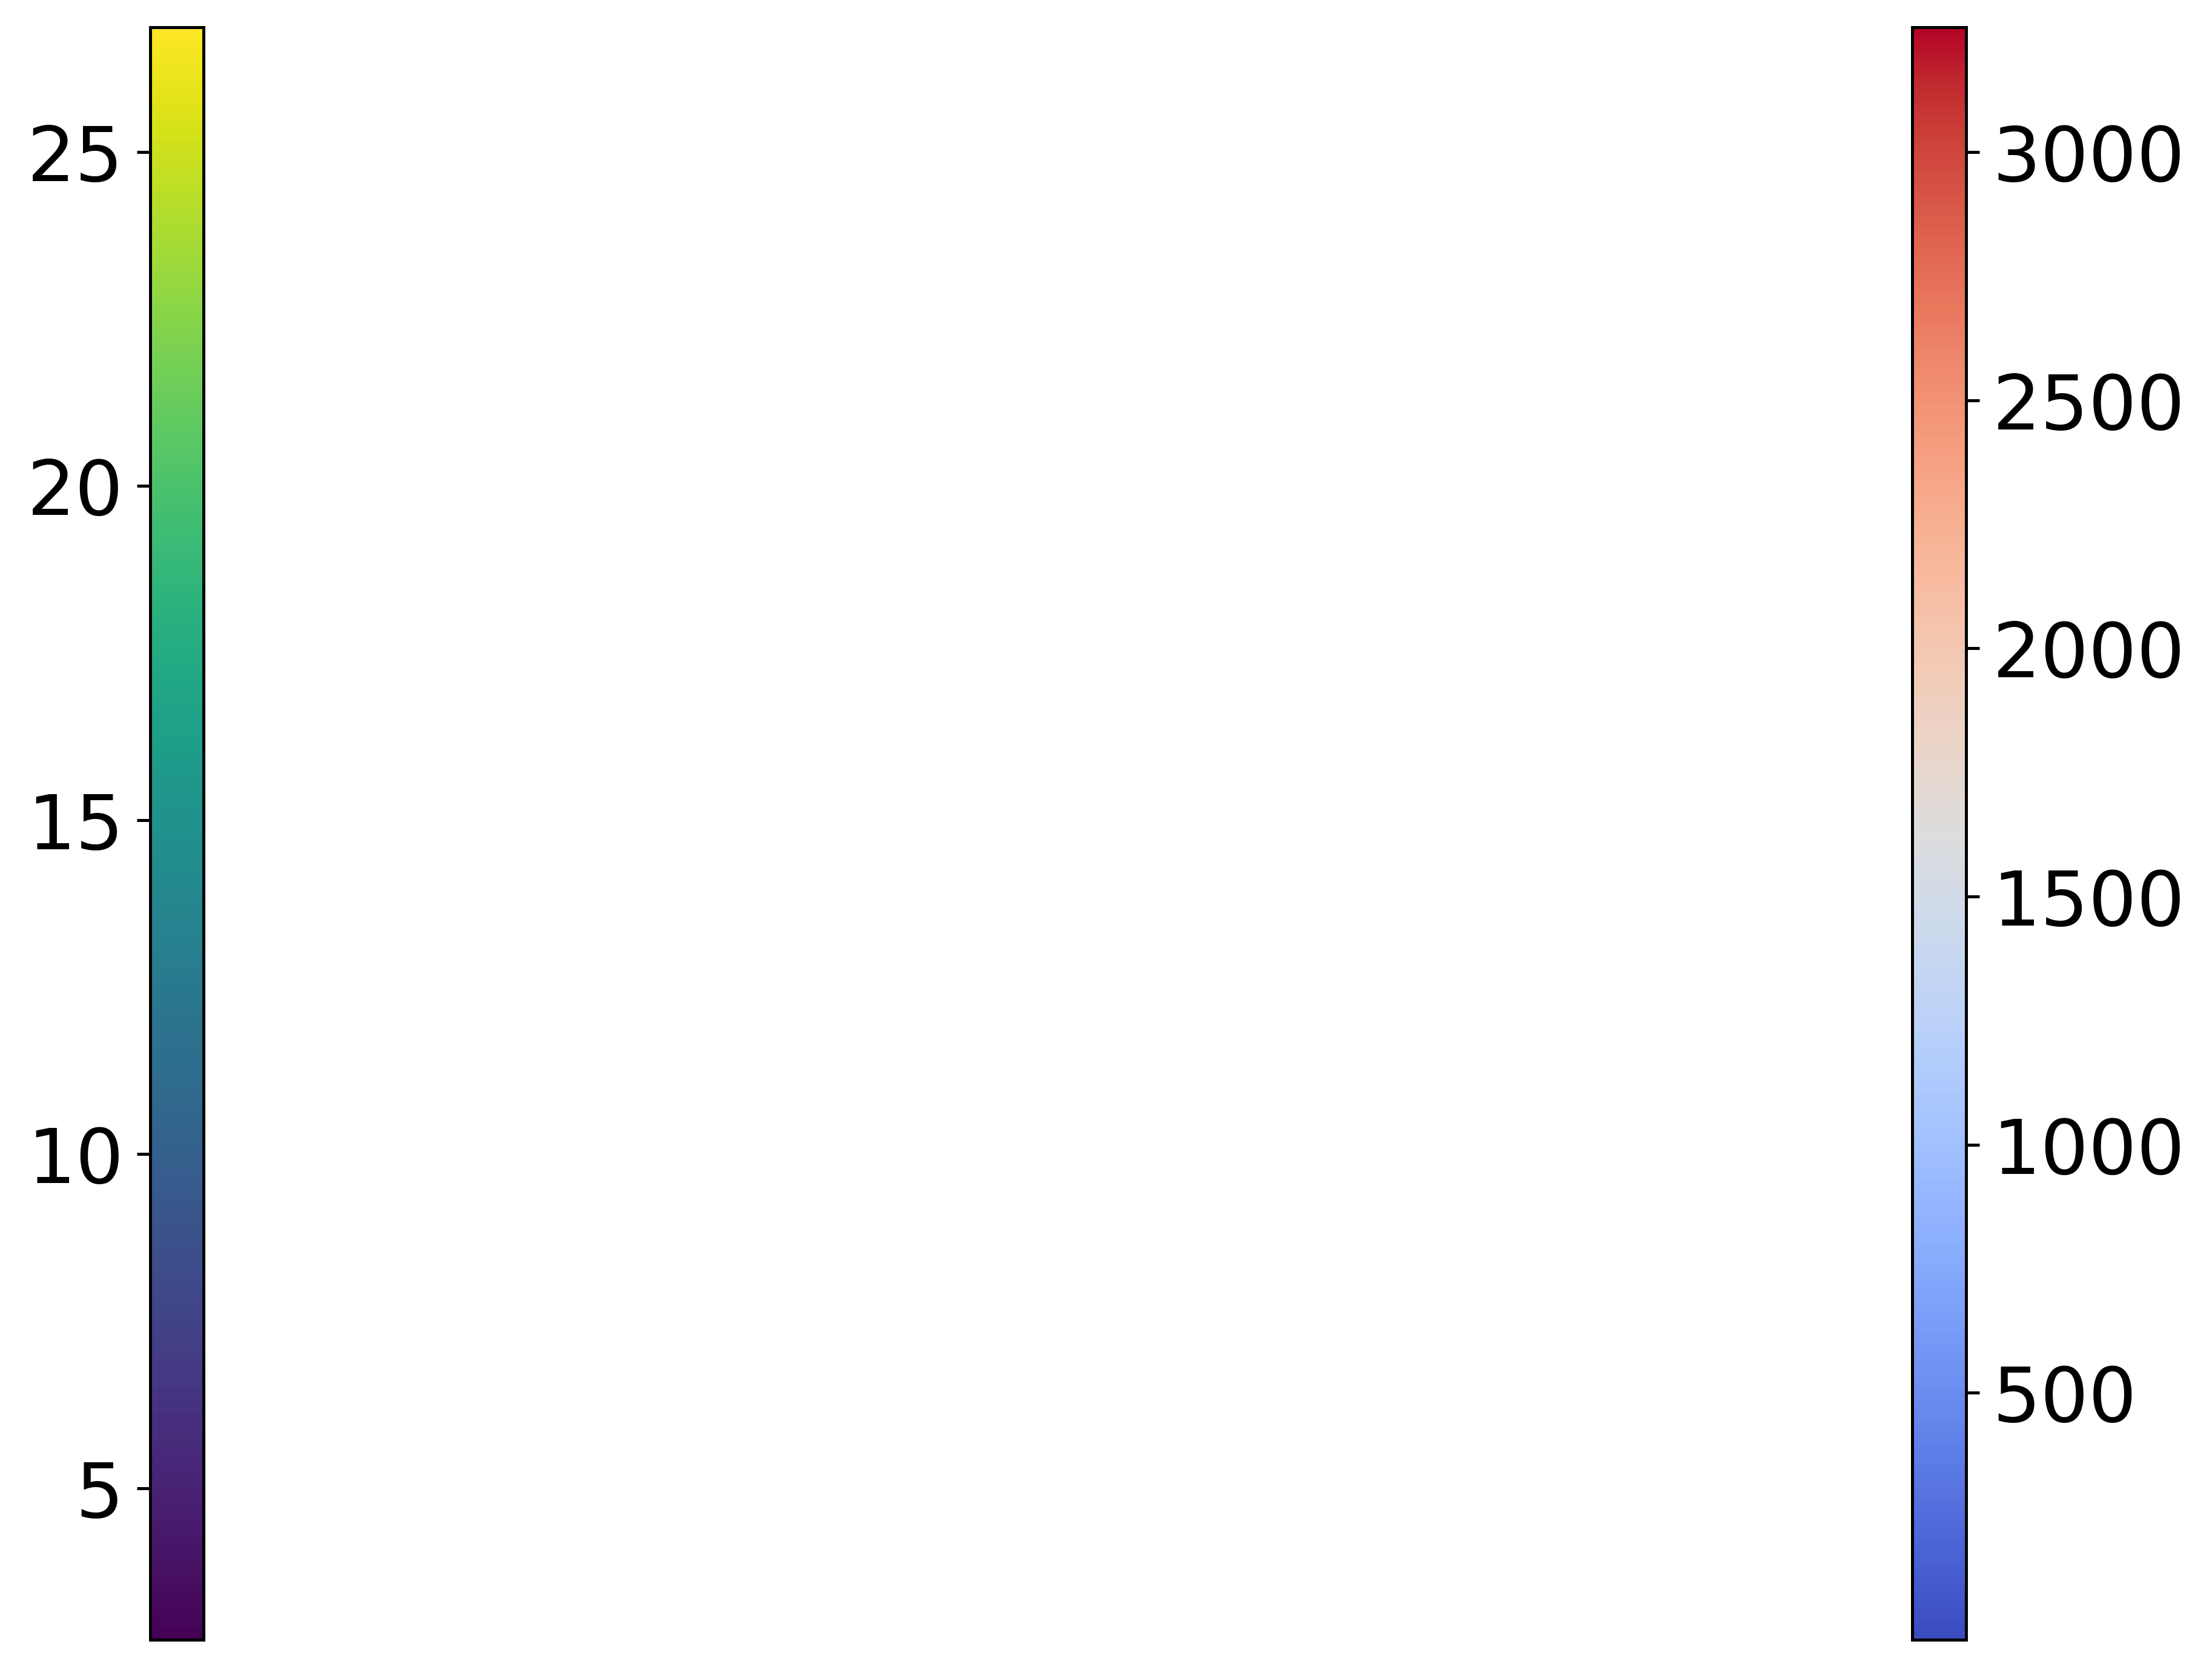

In [151]:
plot_dual_metric_heatmap_stable(cov_dict=dict_leodian_cov,
                         keys=keys,
                         method_lower='airm',
                         method_upper='kl',
                         title='Covariance Difference Metrics',
                         cmap_lower='viridis',
                         cmap_upper='coolwarm',
                         save_fig=False,
                         nat_select_dict=nat.dict_f,
                         figsize=(8, 6),
                         )

In [83]:
plot_dual_metric_heatmap_stable(dict=dict_leodian_cov,
                         keys=keys,
                         method_lower='airm',
                         method_upper='rv',
                         title='Covariance Difference Metrics',
                         cmap_lower='viridis',
                         cmap_upper='coolwarm',
                         save_fig=False,
                         nat_select_dict=nat.dict_f,
                         figsize=(12, 6)
                         )

TypeError: plot_dual_metric_heatmap_stable() got an unexpected keyword argument 'dict'

## Plotting

In [ ]:
distances_kl = []
distances_airm = []
dist_keys = keys[:-1]
for k in dist_keys:
    dist_kl = compute_matrix_distance(mat1=dict_leodian_cov[k]*1e+9, mat2=dict_leodian_cov[keys[-1]]*1e+9, method='kl', mu1=nat.dict_f[k].mean(), mu2=nat.dict_f[keys[-1]].mean())
    dist_airm = compute_matrix_distance(mat1=dict_leodian_cov[k]*1e+9, mat2=dict_leodian_cov[keys[-1]]*1e+9, method='airm', mu1=nat.dict_f[k].mean(), mu2=nat.dict_f[keys[-1]].mean())
    distances_kl.append(dist_kl)
    distances_airm.append(dist_airm)

dist_keys = keys[:-1]                      # already defined
sample_sizes = np.array([int(k) for k in dist_keys])
# x = np.log2(sample_sizes)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_cov_convergence(
        sample_sizes,
        distances_kl,
        distances_airm,
        *,
        title="Covariance Convergence",
        title_fontsize=14,
        xaxis_fontsize=12,
        xaxis_ticksize=12,
        yaxis_fontsize=12,
        legend_fontsize=12,
        lw_kl=2,
        lw_airm=2,
        log_base=2,  # choose 2 or 10
        figsize=(8, 6),
        dpi=150,
    ):
    """
    sample_sizes: list/array of N values
    distances_kl: list of KL distances
    distances_airm: list of AIRM distances
    """

    sample_sizes = np.array(sample_sizes)

    # --- convert x-axis to logarithmic base ---
    if log_base == 2:
        x = np.log2(sample_sizes)
        xlabel = r'$\log_2(\mathrm{number\ of\ samples})$'
    else:
        x = np.log10(sample_sizes)
        xlabel = r'$\log_{10}(\mathrm{number\ of\ samples})$'

    # --- main figure ---
    fig, ax1 = plt.subplots(figsize=figsize, dpi=dpi)

    # KL on left y-axis
    color_kl = 'tab:blue'
    ln1 = ax1.plot(
        x, distances_kl,
        marker='o', markersize=2*lw_kl, lw=lw_kl, linestyle='-',
        label='Kullback–Leibler', color=color_kl
    )
    ax1.set_xlabel(xlabel, fontsize=xaxis_fontsize)
    ax1.set_ylabel('KL divergence', color=color_kl, fontsize=yaxis_fontsize)
    ax1.tick_params(axis='y', labelcolor=color_kl, labelsize=yaxis_fontsize)
    ax1.tick_params(axis='x', labelsize=xaxis_fontsize)
    ax1.grid(True, which='both', alpha=0.25)

    # --- keep the actual sample sizes as tick labels ---
    ax1.set_xticks(x)
    ax1.set_xticklabels([str(N) for N in sample_sizes], fontsize=xaxis_ticksize)

    # AIRM on right y-axis
    ax2 = ax1.twinx()
    color_airm = 'tab:orange'
    ln2 = ax2.plot(
        x, distances_airm,
        marker='s', markersize=2*lw_airm, lw=lw_airm, linestyle='--',
        label='AIRM distance', color=color_airm
    )
    ax2.set_ylabel('AIRM distance', color=color_airm, fontsize=yaxis_fontsize)
    ax2.tick_params(axis='y', labelcolor=color_airm, labelsize=yaxis_fontsize)

    # Title
    ax1.set_title(title, fontsize=title_fontsize, pad=10)

    # Combined legend
    lines = ln1 + ln2
    labels = [l.get_label() for l in lines]
    ax1.legend(
        lines, labels,
        loc='upper right',
        frameon=False,
        fontsize=legend_fontsize
    )

    fig.tight_layout()
    plt.show()

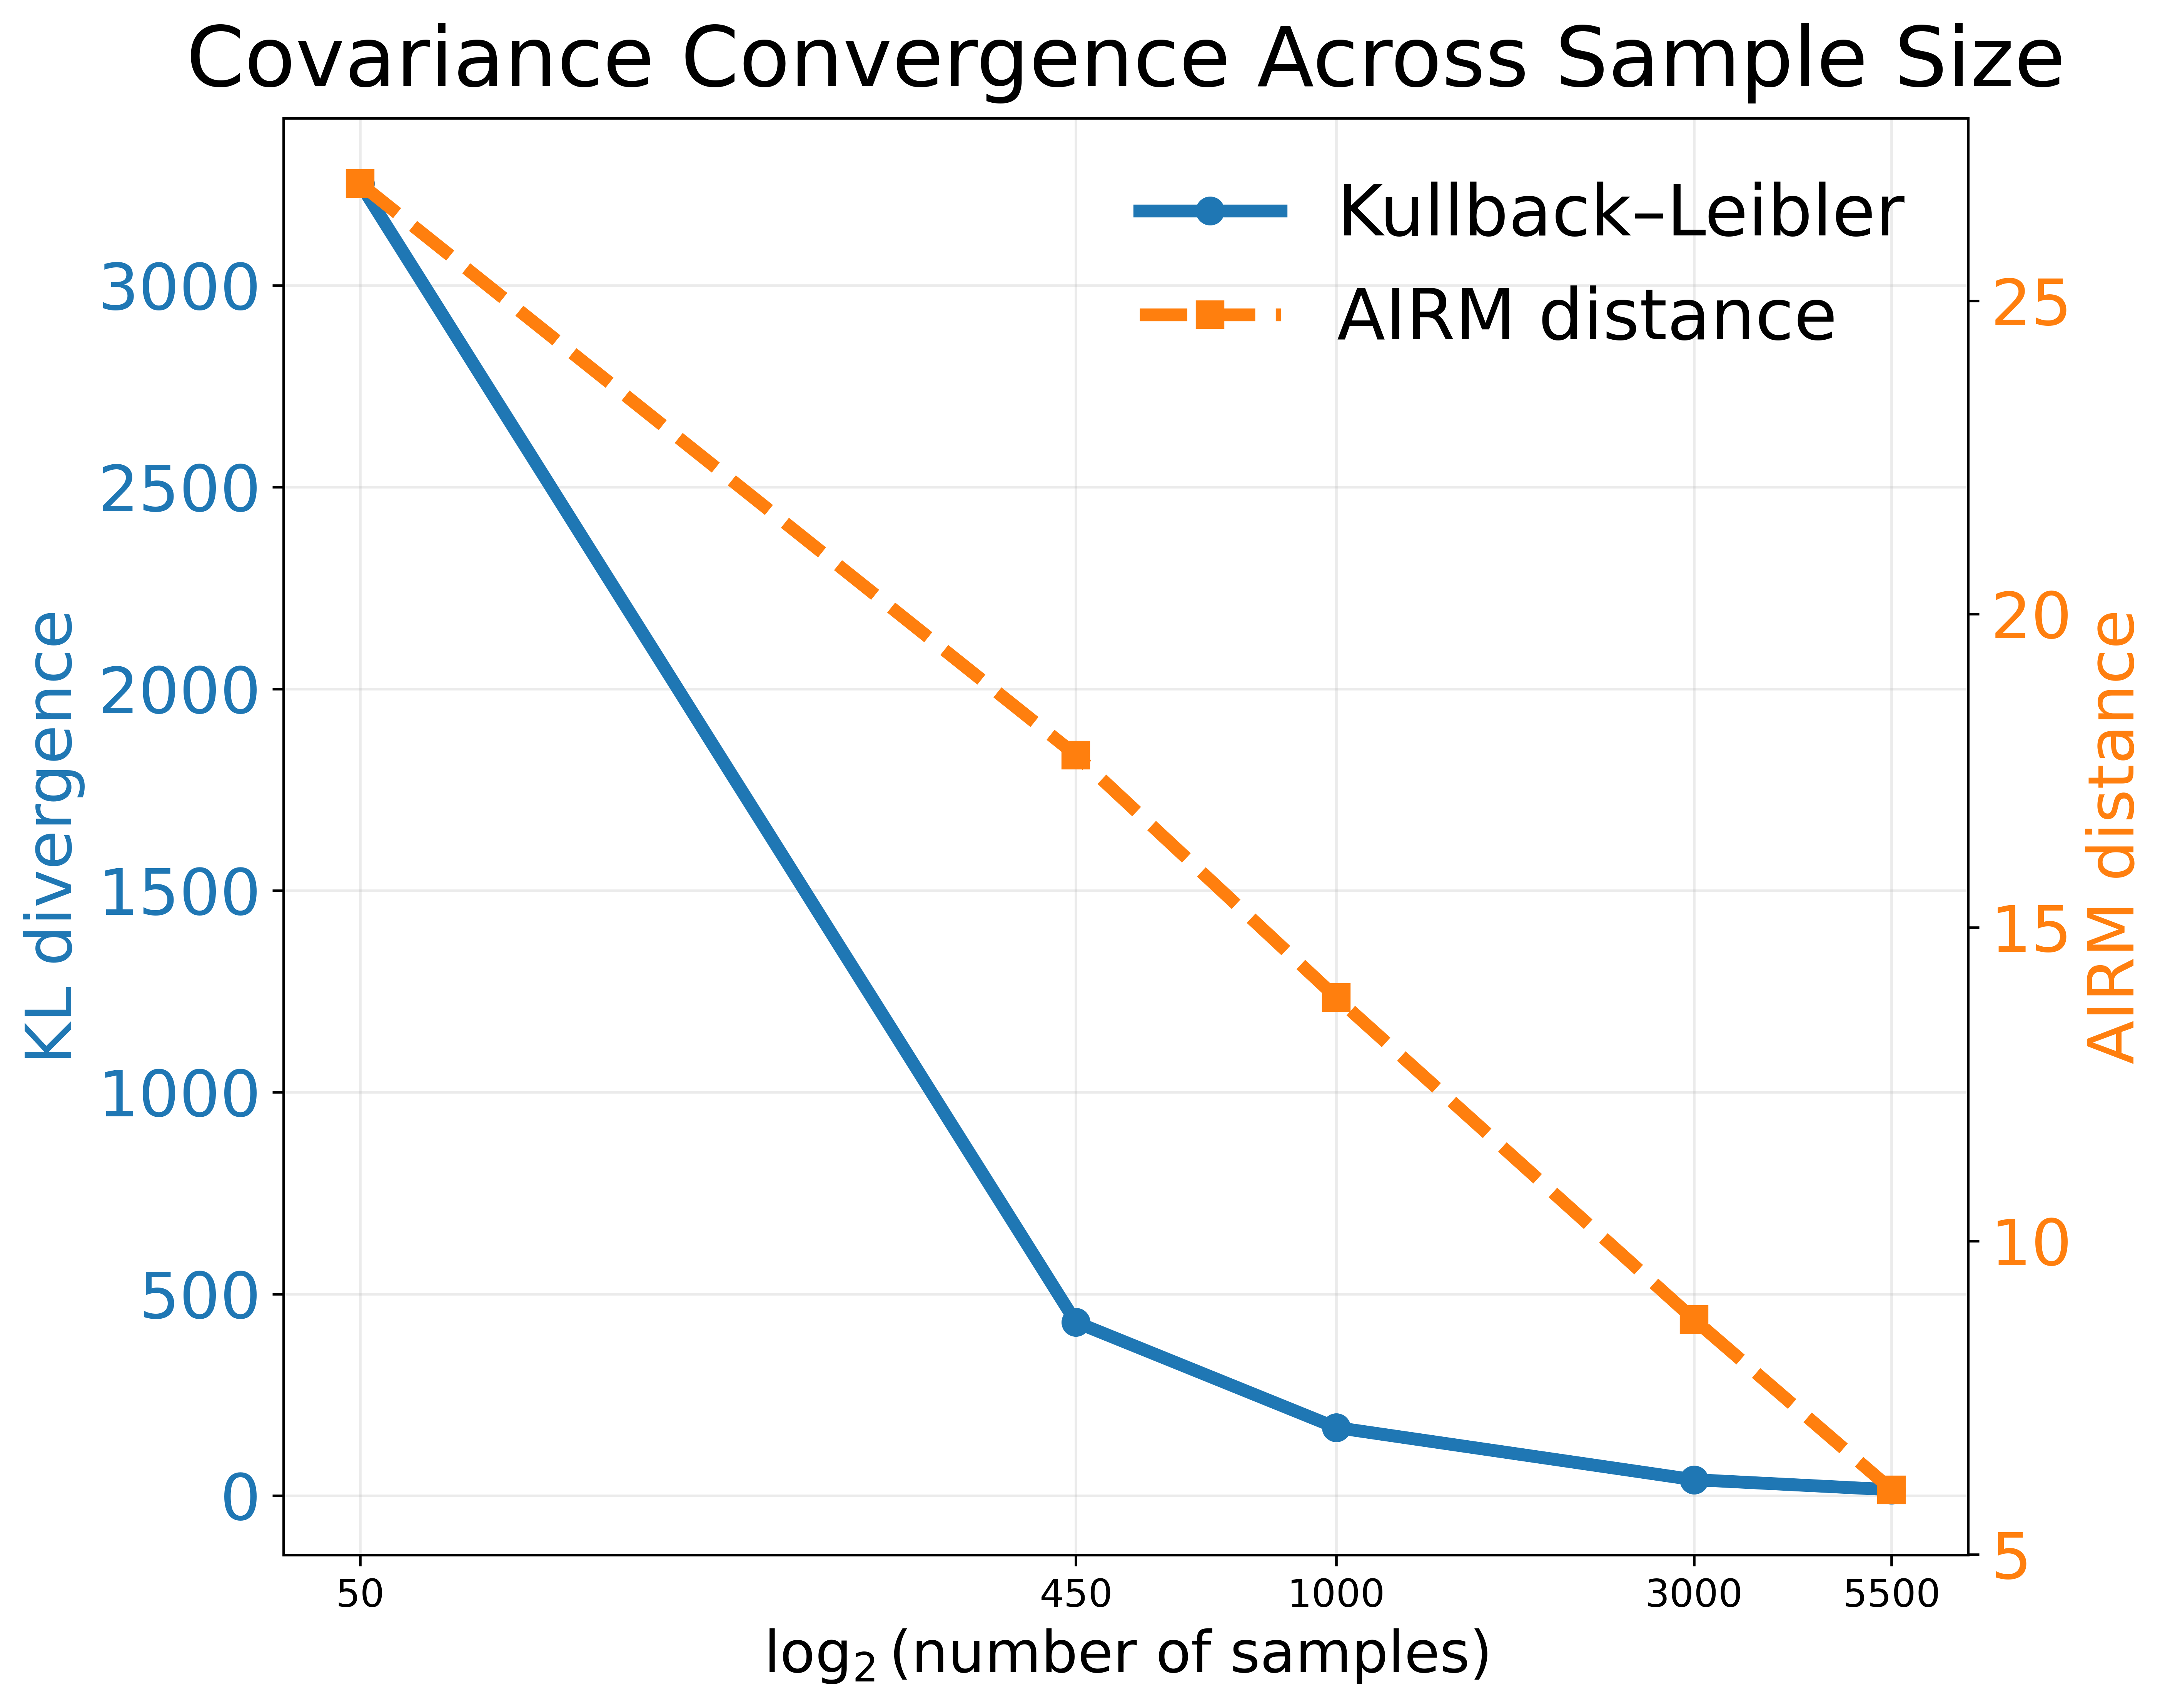

In [ ]:
plot_cov_convergence(
    sample_sizes,
    distances_kl,
    distances_airm,
    title="Covariance Convergence Across Sample Size",
    title_fontsize=26,
    xaxis_fontsize=18,
    xaxis_ticksize=12,
    yaxis_fontsize=20,
    legend_fontsize=22,
    log_base=2,
    lw_kl=4,
    lw_airm=4,
    figsize=(9.5, 7.5),
    dpi=600,
)